# Analysis for Results and Discussion
Used local results from eval_results folder

In [141]:
# 1. Import data
import pandas as pd
from pathlib import Path
raw = pd.read_csv(Path("eval_results/tier1_acl_results.csv"))
raw.head()

,tier,split,talk_id,condition,noise_type,snr_db,noise_seed,wer,cer,kter,term_presence_recall,terms_present,signal_snr_improvement_db,rtf,audio_duration_s,seconds,language
0,1,eval,2022.acl-long.111,arm_a,none,NaN,NaN,0.262058,0.105971,0.840580,0.840580,69,NaN,0.071672,713.015,51.102938,en
1,1,eval,2022.acl-long.111,hp,none,NaN,NaN,0.250000,0.096088,0.840580,0.840580,69,NaN,0.088053,713.015,62.783083,en
2,1,eval,2022.acl-long.111,hp+sg,none,NaN,NaN,0.250000,0.096088,0.840580,0.840580,69,NaN,0.084554,713.015,60.288582,en
3,1,eval,2022.acl-long.111,hp_wiener,none,NaN,NaN,0.250000,0.096088,0.840580,0.840580,69,NaN,0.093124,713.015,66.399137,en
4,1,eval,2022.acl-long.111,hp_wiener_oa,none,NaN,NaN,0.251608,0.095676,0.826087,0.826087,69,NaN,0.090786,713.015,64.731522,en


In [142]:
%matplotlib inline
# 2. Import dependencies
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi": 110})

In [143]:
# 3. Create dataframe
df = raw.copy()
df = df.drop_duplicates()
df["snr_db"] = df["snr_db"].fillna("clean").map(lambda v: "clean" if v == "clean" else str(int(float(v))))
df["noise_seed"] = df["noise_seed"].fillna("clean").astype(str)
df["snr_db"] = pd.Categorical(df["snr_db"], categories=["clean", "20", "10", "5", "0"], ordered=True)
df["snr_num"] = df["snr_db"].astype(str).map({"clean": np.nan, "20": 20.0, "10": 10.0, "5": 5.0, "0": 0.0})
df["condition"] = pd.Categorical(df["condition"], categories=["arm_a", "hp", "hp+sg", "hp_wiener", "hp_wiener_oa", "hp_ffmpeg"], ordered=True)
df = df.drop(columns=["term_presence_recall", "tier", "split", "language"], errors="ignore")
df.head()

,talk_id,condition,noise_type,snr_db,noise_seed,wer,cer,kter,terms_present,signal_snr_improvement_db,rtf,audio_duration_s,seconds,snr_num
0,2022.acl-long.111,arm_a,none,clean,clean,0.262058,0.105971,0.840580,69,NaN,0.071672,713.015,51.102938,NaN
1,2022.acl-long.111,hp,none,clean,clean,0.250000,0.096088,0.840580,69,NaN,0.088053,713.015,62.783083,NaN
2,2022.acl-long.111,hp+sg,none,clean,clean,0.250000,0.096088,0.840580,69,NaN,0.084554,713.015,60.288582,NaN
3,2022.acl-long.111,hp_wiener,none,clean,clean,0.250000,0.096088,0.840580,69,NaN,0.093124,713.015,66.399137,NaN
4,2022.acl-long.111,hp_wiener_oa,none,clean,clean,0.251608,0.095676,0.826087,69,NaN,0.090786,713.015,64.731522,NaN


In [144]:
# 4. Explore data
rows_cols = (df.shape, list(df.columns))
grouped = (df.groupby(["condition", "noise_type"], observed=True)["wer"]
              .mean().unstack("noise_type").round(4))
rows_cols, grouped

(((390, 14),
  ['talk_id',
   'condition',
   'noise_type',
   'snr_db',
   'noise_seed',
   'wer',
   'cer',
   'kter',
   'terms_present',
   'signal_snr_improvement_db',
   'rtf',
   'audio_duration_s',
   'seconds',
   'snr_num']),
 noise_type    demand:DKITCHEN  demand:DLIVING  demand:DWASHING    none
 condition                                                             
 arm_a                  0.1984          0.2178           0.1698  0.1696
 hp                     0.1994          0.2136           0.1703  0.1677
 hp+sg                  0.1991          0.2127           0.1703  0.1677
 hp_wiener              0.1999          0.2126           0.1703  0.1677
 hp_wiener_oa           0.1971          0.2174           0.1715  0.1685
 hp_ffmpeg              0.2056          0.2239           0.1766  0.1754)

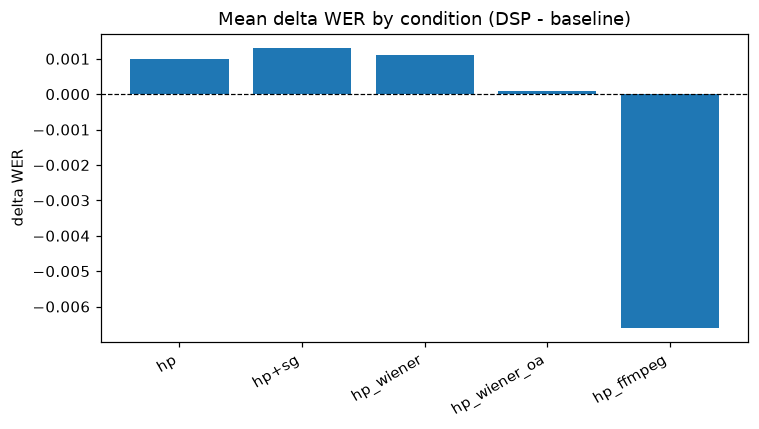

In [145]:
# Q1: Does DSP improve transcription? (paired deltas vs baseline)
keys = ["talk_id", "noise_type", "snr_db", "noise_seed"]
base = (df[df.condition == "arm_a"][keys + ["wer"]]
        .rename(columns={"wer": "wer_base"}))
d = df[df.condition != "arm_a"].merge(base, on=keys, how="left", validate="many_to_one")
d["delta_wer"] = d["wer_base"] - d["wer"]  # flipped: positive = improvement
q1 = (d.groupby("condition", observed=True)
        .agg(mean_delta_wer=("delta_wer", "mean"),
             win_rate=("delta_wer", lambda s: (s > 0).mean()))
        .round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(q1.index.astype(str), q1["mean_delta_wer"])
ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_title("Mean delta WER by condition (DSP - baseline)")
ax.set_ylabel("delta WER")
ax.set_xticklabels(q1.index.astype(str), rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [146]:
# Q2: Which DSP combo is most / least impactful?
q2 = (d.groupby("condition", observed=True)["delta_wer"]
        .mean().sort_values(ascending=False).reset_index())
q2.columns = ["condition", "mean_delta_wer"]
q2["rank"] = range(1, len(q2) + 1)
q2.round(4)


,condition,mean_delta_wer,rank
0,hp+sg,0.0013,1
1,hp_wiener,0.0011,2
2,hp,0.0010,3
3,hp_wiener_oa,0.0001,4
4,hp_ffmpeg,-0.0066,5


In [147]:
# Q3: Mechanism, conditions, and cost
expl = d.copy()
expl["environment"] = np.where(expl["noise_type"].astype(str) == "none", "clean", "noisy")
cost_base = (df[df.condition == "arm_a"][keys + ["rtf"]].rename(columns={"rtf": "rtf_base"}))
expl = expl.merge(cost_base, on=keys, how="left", validate="many_to_one")
expl["delta_rtf"] = expl["rtf"] - expl["rtf_base"]
q3 = (expl.groupby("condition", observed=True)
            .agg(mean_delta_wer=("delta_wer", "mean"),
                 mean_delta_rtf=("delta_rtf", "mean"),
                 win_rate=("delta_wer", lambda s: (s > 0).mean()))
            .round(4))
q3


,mean_delta_wer,mean_delta_rtf,win_rate
condition,,,
hp,0.0010,0.0144,0.4000
hp+sg,0.0013,0.0144,0.4154
hp_wiener,0.0011,0.0150,0.4154
hp_wiener_oa,0.0001,0.0136,0.4308
hp_ffmpeg,-0.0066,0.0108,0.1692


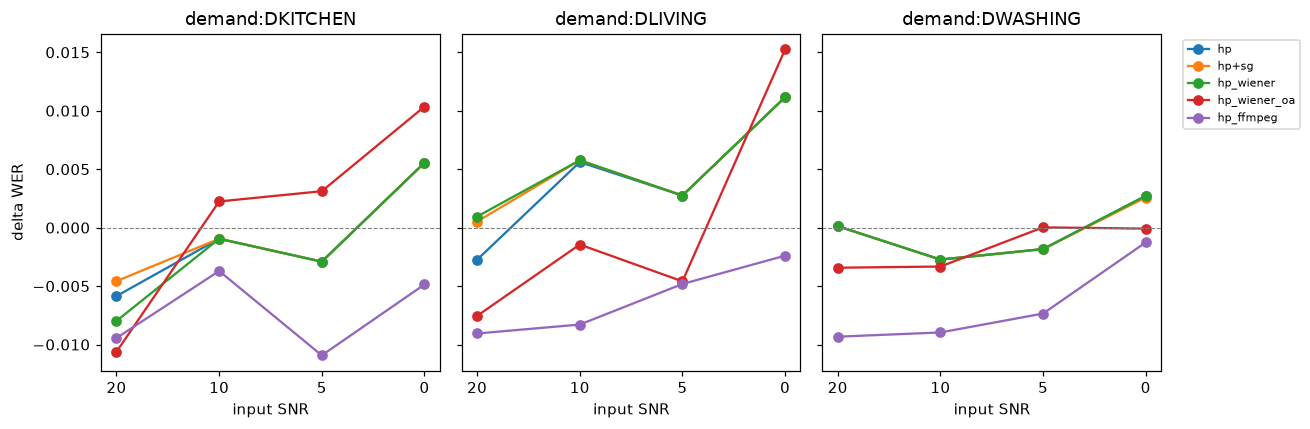

In [148]:
# Q3 (viz): delta WER vs input SNR by noise type
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, nt in zip(axes, ["demand:DKITCHEN", "demand:DLIVING", "demand:DWASHING"]):
    sub = d[d["noise_type"].astype(str) == nt]
    for cond in ["hp", "hp+sg", "hp_wiener", "hp_wiener_oa", "hp_ffmpeg"]:
        g = sub[sub["condition"].astype(str) == cond].groupby("snr_db", observed=True)["delta_wer"].mean()
        ax.plot(g.index.astype(str), g.values, marker="o", label=cond)
    ax.set_title(nt)
    ax.set_xlabel("input SNR")
    ax.axhline(0, color="grey", linestyle="--", linewidth=0.7)
axes[0].set_ylabel("delta WER")
axes[-1].legend(fontsize=7, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

## A. Spread of the paired deltas (Q1)

Aim: how consistent is the effect across files? Is the mean small relative to the variability?

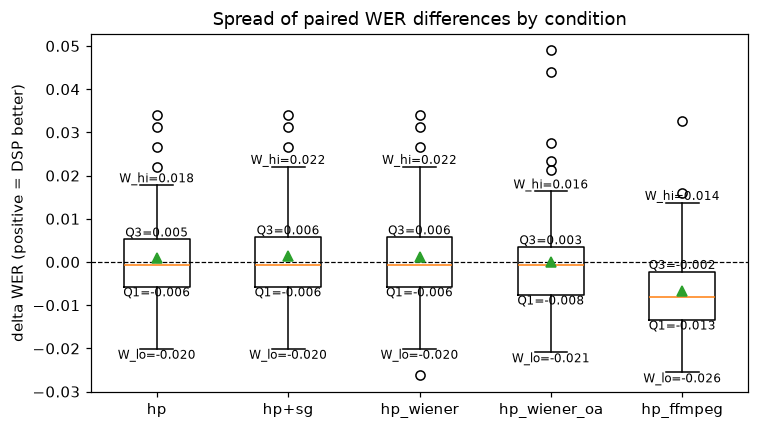

In [149]:
# A. spread of paired deltas
spread = d.groupby("condition", observed=True)["delta_wer"].agg(
    n="size", mean="mean", sd=lambda s: s.std(ddof=1),
    sem=lambda s: s.sem(ddof=1),
    q25=lambda s: s.quantile(0.25), median="median", q75=lambda s: s.quantile(0.75),
    minimum="min", maximum="max",
).reset_index()
spread["iqr"] = spread["q75"] - spread["q25"]
spread["cv_pct"] = (spread["sd"] / spread["mean"].replace(0, np.nan)).abs() * 100
spread = spread[["condition", "n", "mean", "sd", "sem", "cv_pct", "q25", "median", "q75", "iqr", "minimum", "maximum"]].round(4)
spread

fig, ax = plt.subplots(figsize=(7, 4))
dsp_conds = [c for c in d["condition"].cat.categories if c != "arm_a"]
bp = ax.boxplot([d.loc[d["condition"] == c, "delta_wer"].to_numpy(float) for c in dsp_conds],
               tick_labels=dsp_conds, showmeans=True)
ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
# annotate box (Q1/Q3) and whisker (non-outlier) edges
for i in range(len(dsp_conds)):
    box_y = bp["boxes"][i].get_ydata()
    q1, q3 = float(min(box_y)), float(max(box_y))
    lo = float(bp["whiskers"][2 * i].get_ydata()[-1])
    hi = float(bp["whiskers"][2 * i + 1].get_ydata()[-1])
    ax.text(i + 1, q3, f"Q3={q3:.3f}", ha="center", va="bottom", fontsize=8)
    ax.text(i + 1, q1, f"Q1={q1:.3f}", ha="center", va="top", fontsize=8)
    ax.text(i + 1, hi, f"W_hi={hi:.3f}", ha="center", va="bottom", fontsize=8)
    ax.text(i + 1, lo, f"W_lo={lo:.3f}", ha="center", va="top", fontsize=8)
ax.set_ylabel("delta WER (positive = DSP better)")
ax.set_title("Spread of paired WER differences by condition")
plt.tight_layout()
plt.show()


Reading it: where SD is an order of magnitude larger than the mean, the average effect is being carried by a mix of small wins and losses; the boxplot shows whether a few extremes dominate.

## B. Cluster bootstrap CI, resampling talk_id (Q1, Q2)

Aim: how much would the average effect change with a different set of talks, and does the plausible range include zero? Only 5 talks, so CIs (especially per SNR) are wide.

In [150]:
# B. reusable cluster bootstrap: resample whole talks
rng = np.random.default_rng(0)

def cluster_ci(g, value_col="delta_wer", cluster_col="talk_id", n_boot=5000):
    clusters = g[cluster_col].unique()
    vals = g[value_col].to_numpy(float)
    cl = g[cluster_col].to_numpy()
    idx_by_cluster = {c: np.where(cl == c)[0] for c in clusters}
    boot = np.empty(n_boot, dtype=float)
    for b in range(n_boot):
        chosen = rng.choice(clusters, size=len(clusters), replace=True)
        rows = np.concatenate([idx_by_cluster[c] for c in chosen])
        boot[b] = vals[rows].mean()
    return float(vals.mean()), float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))

dsp_conds = [c for c in d["condition"].cat.categories if c != "arm_a"]

ci_rows = []
for c in dsp_conds:
    sub = d[d["condition"] == c]
    mean, lo, hi = cluster_ci(sub)
    ci_rows.append({"condition": c, "mean_delta_wer": mean, "ci_lo": lo, "ci_hi": hi,
                    "excludes_zero": bool((lo > 0) or (hi < 0))})
ci_tbl = pd.DataFrame(ci_rows).round(4)
ci_tbl

,condition,mean_delta_wer,ci_lo,ci_hi,excludes_zero
0,hp,0.0010,-0.0015,0.0043,False
1,hp+sg,0.0013,-0.0015,0.0053,False
2,hp_wiener,0.0011,-0.0015,0.0047,False
3,hp_wiener_oa,0.0001,-0.0030,0.0041,False
4,hp_ffmpeg,-0.0066,-0.0073,-0.0057,True


In [151]:
# B. per condition x input SNR
snr_rows = []
for c in dsp_conds:
    for snr in ["clean", "20", "10", "5", "0"]:
        sub = d[(d["condition"].astype(str) == c) & (d["snr_db"].astype(str) == snr)]
        if len(sub) == 0:
            continue
        mean, lo, hi = cluster_ci(sub)
        snr_rows.append({"condition": c, "snr_db": snr, "n": len(sub),
                         "mean_delta_wer": mean, "ci_lo": lo, "ci_hi": hi,
                         "excludes_zero": bool((lo > 0) or (hi < 0))})
ci_snr = pd.DataFrame(snr_rows).round(4)
ci_snr

,condition,snr_db,n,mean_delta_wer,ci_lo,ci_hi,excludes_zero
0,hp,clean,5,0.0019,-0.0067,0.0106,False
1,hp,20,15,-0.0028,-0.0058,-0.0007,True
2,hp,10,15,0.0006,-0.0041,0.0060,False
3,hp,5,15,-0.0007,-0.0028,0.0020,False
4,hp,0,15,0.0065,-0.0033,0.0177,False
5,hp+sg,clean,5,0.0019,-0.0067,0.0106,False
6,hp+sg,20,15,-0.0013,-0.0052,0.0021,False
7,hp+sg,10,15,0.0007,-0.0040,0.0058,False
8,hp+sg,5,15,-0.0007,-0.0028,0.0020,False
9,hp+sg,0,15,0.0064,-0.0033,0.0175,False


Reading it: a CI containing 0 means the data are compatible with no effect across a different draw of talks; the per-SNR CIs are based on 15 rows each and are necessarily wide.

## C. Paired tests with multiple-comparison correction (Q1, Q2)

Aim: is each improvement bigger than chance, and how big is it in standardized terms? Effect sizes accompany every p-value.

In [152]:
# optional statsmodels import with fallback
try:
    from statsmodels.stats.multitest import multipletests
except Exception:
    def multipletests(pvals, method="holm"):
        p = np.asarray(pvals, dtype=float)
        m = len(p)
        order = np.argsort(p)
        adj = np.empty(m)
        prev = 0.0
        for rank, idx in enumerate(order):
            val = min(1.0, p[idx] * (m - rank))
            val = max(val, prev)
            adj[idx] = val
            prev = val
        return adj, None, None, None

def holm(pvals):
    arr = np.asarray(pvals, dtype=float)
    try:
        from statsmodels.stats.multitest import multipletests as _mp
        return np.asarray(_mp(arr, method="holm")[1], dtype=float)
    except Exception:
        m = len(arr)
        order = np.argsort(arr)
        adj = np.empty(m)
        prev = 0.0
        for rank, idx in enumerate(order):
            val = min(1.0, arr[idx] * (m - rank))
            val = max(val, prev)
            adj[idx] = val
            prev = val
        return adj

def safe_wilcoxon_p(x):
    x = np.asarray(x, dtype=float)
    if len(x) == 0:
        return np.nan
    if np.all(x == 0):
        return 1.0
    try:
        return float(stats.wilcoxon(x, zero_method="wilcox").pvalue)
    except ValueError:
        return np.nan

t_rows = []
for c in dsp_conds:
    x = d.loc[d["condition"] == c, "delta_wer"].to_numpy(float)
    sd = x.std(ddof=1)
    tr = stats.ttest_1samp(x, 0.0)
    t_rows.append({"condition": c, "n": len(x), "mean_delta": x.mean(), "sd": sd,
                   "t_pvalue": tr.pvalue, "wilcoxon_p": safe_wilcoxon_p(x),
                   "cohens_dz": (x.mean() / sd if sd > 0 else np.nan)})
t_tbl = pd.DataFrame(t_rows).round(4)
t_tbl["wilcoxon_p_holm"] = holm(t_tbl["wilcoxon_p"].fillna(1.0).to_numpy()).round(4)
t_tbl


,condition,n,mean_delta,sd,t_pvalue,wilcoxon_p,cohens_dz,wilcoxon_p_holm
0,hp,65,0.0010,0.0104,0.4496,0.9441,0.0944,1.0
1,hp+sg,65,0.0013,0.0104,0.3035,0.8089,0.1287,1.0
2,hp_wiener,65,0.0011,0.0109,0.4121,0.8361,0.1024,1.0
3,hp_wiener_oa,65,0.0001,0.0126,0.9594,0.2626,0.0063,1.0
4,hp_ffmpeg,65,-0.0066,0.0105,0.0000,0.0000,-0.6311,0.0


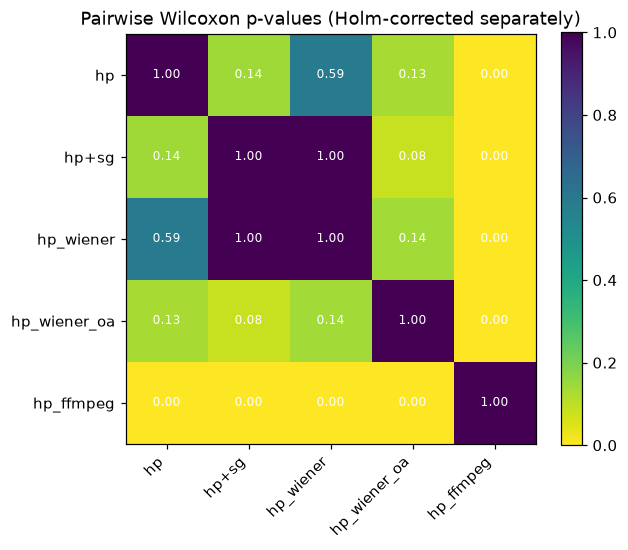

In [153]:
# C. pairwise Wilcoxon between DSP conditions (Holm across 10 pairs) + heatmap
pivot_paired = d.pivot_table(index=["talk_id", "noise_type", "snr_db"], columns="condition", values="delta_wer")
assert not pivot_paired.isna().any().any()

pair_rows = []
p_mat = pd.DataFrame(1.0, index=dsp_conds, columns=dsp_conds)
for i in range(len(dsp_conds)):
    for j in range(i + 1, len(dsp_conds)):
        a, b = dsp_conds[i], dsp_conds[j]
        xa = pivot_paired[a].to_numpy(float)
        xb = pivot_paired[b].to_numpy(float)
        try:
            p = float(stats.wilcoxon(xa, xb, zero_method="wilcox").pvalue)
        except ValueError:
            p = np.nan
        pair_rows.append({"pair": f"{a} vs {b}", "mean_diff_a_minus_b": float(np.mean(xa - xb)), "p_raw": p})
        p_mat.loc[a, b] = p
        p_mat.loc[b, a] = p

pair_tbl = pd.DataFrame(pair_rows)
pair_tbl["p_holm"] = holm(pair_tbl["p_raw"].fillna(1.0).to_numpy())
pair_tbl = pair_tbl.round(4)
pair_tbl

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(p_mat.to_numpy(dtype=float), vmin=0, vmax=1, cmap="viridis_r")
ax.set_xticks(range(len(dsp_conds)))
ax.set_yticks(range(len(dsp_conds)))
ax.set_xticklabels(dsp_conds, rotation=45, ha="right")
ax.set_yticklabels(dsp_conds)
for i in range(len(dsp_conds)):
    for j in range(len(dsp_conds)):
        ax.text(j, i, f"{p_mat.iloc[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
ax.set_title("Pairwise Wilcoxon p-values (Holm-corrected separately)")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


Reading it: compare each Wilcoxon p (Holm) with its Cohen's dz and cluster CI; a consistent, small effect can be real yet practically modest.

## D. Equivalence test, TOST (Q1)

Aim: when no significant difference is found, can we positively claim the effect is practically negligible?

In [154]:
# D. TOST equivalence test (margin = 0.5 pp WER, a judgment call)
margin = 0.005

def tost_p(x, m):
    p1 = stats.ttest_1samp(x, -m, alternative="greater").pvalue
    p2 = stats.ttest_1samp(x, m, alternative="less").pvalue
    return float(max(p1, p2))

tost_rows = []
for c in dsp_conds:
    x = d.loc[d["condition"] == c, "delta_wer"].to_numpy(float)
    p = tost_p(x, margin)
    tost_rows.append({"condition": c, "margin": margin, "tost_p": p,
                      "verdict": "equivalent within ±margin" if p < 0.05 else "inconclusive/not equivalent"})
tost_tbl = pd.DataFrame(tost_rows).round(4)
tost_tbl

,condition,margin,tost_p,verdict
0,hp,0.005,0.0014,equivalent within ±margin
1,hp+sg,0.005,0.0030,equivalent within ±margin
2,hp_wiener,0.005,0.0028,equivalent within ±margin
3,hp_wiener_oa,0.005,0.0012,equivalent within ±margin
4,hp_ffmpeg,0.005,0.8922,inconclusive/not equivalent


In [155]:
# D. sensitivity of TOST to the margin
sens_rows = []
for m in [0.0025, 0.005, 0.010]:
    for c in dsp_conds:
        x = d.loc[d["condition"] == c, "delta_wer"].to_numpy(float)
        sens_rows.append({"margin": m, "condition": c, "tost_p": tost_p(x, m),
                          "verdict": "equivalent" if tost_p(x, m) < 0.05 else "not equivalent"})
sens_tbl = pd.DataFrame(sens_rows).round(4)
sens_tbl

,margin,condition,tost_p,verdict
0,0.0025,hp,0.1235,not equivalent
1,0.0025,hp+sg,0.1848,not equivalent
2,0.0025,hp_wiener,0.1556,not equivalent
3,0.0025,hp_wiener_oa,0.0629,not equivalent
4,0.0025,hp_ffmpeg,0.9988,not equivalent
5,0.0050,hp,0.0014,equivalent
6,0.0050,hp+sg,0.0030,equivalent
7,0.0050,hp_wiener,0.0028,equivalent
8,0.0050,hp_wiener_oa,0.0012,equivalent
9,0.0050,hp_ffmpeg,0.8922,not equivalent


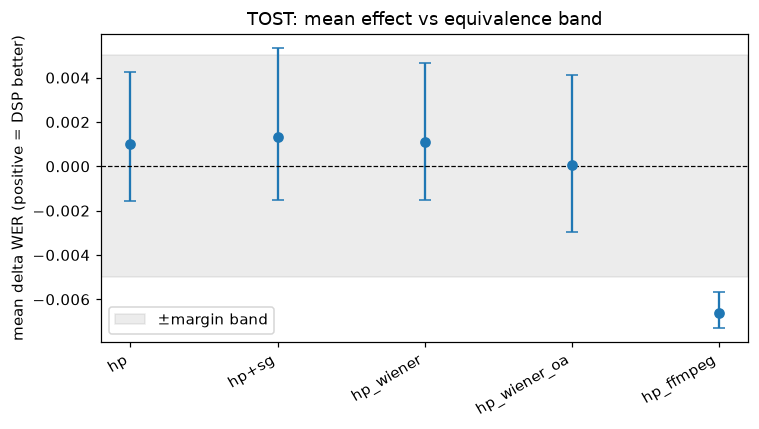

In [156]:
# D. plot mean with CI against the ±margin band
fig, ax = plt.subplots(figsize=(7, 4))
xs = range(len(dsp_conds))
means = [cluster_ci(d[d["condition"] == c])[0] for c in dsp_conds]
los = [cluster_ci(d[d["condition"] == c])[1] for c in dsp_conds]
his = [cluster_ci(d[d["condition"] == c])[2] for c in dsp_conds]
errs = np.vstack([np.array(means) - np.array(los), np.array(his) - np.array(means)])
ax.errorbar(xs, means, yerr=errs, fmt="o", capsize=4)
ax.axhspan(-margin, margin, color="grey", alpha=0.15, label="±margin band")
ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xticks(xs)
ax.set_xticklabels(dsp_conds, rotation=30, ha="right")
ax.set_ylabel("mean delta WER (positive = DSP better)")
ax.set_title("TOST: mean effect vs equivalence band")
ax.legend()
plt.tight_layout()
plt.show()

Reading it: a condition whose CI also sits well inside ±margin strengthens the “no practical effect” claim beyond a plain nonsignificant test.

## E. Sign test on wins/losses (Q1, Q2)

Aim: ignoring magnitude, do wins and losses split 50/50?

In [157]:
# E. sign test
sign_rows = []
for c in dsp_conds:
    x = d.loc[d["condition"] == c, "delta_wer"]
    wins = int((x > 0).sum())
    losses = int((x < 0).sum())
    ties = int((x == 0).sum())
    n_eff = wins + losses
    p = stats.binomtest(wins, n_eff).pvalue if n_eff > 0 else np.nan
    sign_rows.append({"condition": c, "wins": wins, "losses": losses, "ties": ties,
                     "n_eff": n_eff, "p_value": p})
sign_tbl = pd.DataFrame(sign_rows).round(4)
sign_tbl["p_holm"] = holm(sign_tbl["p_value"].fillna(1.0).to_numpy()).round(4)
sign_tbl


,condition,wins,losses,ties,n_eff,p_value,p_holm
0,hp,26,36,3,62,0.2529,1.0
1,hp+sg,27,35,3,62,0.3742,1.0
2,hp_wiener,27,35,3,62,0.3742,1.0
3,hp_wiener_oa,28,36,1,64,0.3817,1.0
4,hp_ffmpeg,11,52,2,63,0.0000,0.0


Reading it: ties carry no directional information and are excluded from the count; this guards against large outliers driving the mean.

## F. Omnibus test and ranking (Q2)

Aim: do the conditions differ from each other at all, so that a ranking is justified?

In [158]:
# F. pivot + Friedman
pivot_fw = d.pivot_table(index=["talk_id", "noise_type", "snr_db"], columns="condition", values="delta_wer")
assert not pivot_fw.isna().any().any()
assert pivot_fw.shape[0] == 65

friedman = stats.friedmanchisquare(*[pivot_fw[c].to_numpy() for c in pivot_fw.columns])
print("Friedman statistic:", round(float(friedman.statistic), 4), "p:", friedman.pvalue)

# re-run without hp_ffmpeg to see if one condition drives it
friedman_no_ff = stats.friedmanchisquare(*[pivot_fw[c].to_numpy() for c in pivot_fw.columns if c != "hp_ffmpeg"])
print("Without hp_ffmpeg: statistic:", round(float(friedman_no_ff.statistic), 4), "p:", friedman_no_ff.pvalue)

# rank stability: best/worst per scenario
best_counts = pivot_fw.idxmax(axis=1).value_counts()
worst_counts = pivot_fw.idxmin(axis=1).value_counts()
best_worst = pd.DataFrame({"best_scenarios": best_counts, "worst_scenarios": worst_counts}).fillna(0).astype(int)
best_worst

Friedman statistic: 54.3914 p: 4.357552747559998e-11
Without hp_ffmpeg: statistic: 17.8654 p: 0.0004688695884742137


,best_scenarios,worst_scenarios
arm_a,0,0
hp,37,9
hp+sg,1,0
hp_wiener,1,1
hp_wiener_oa,18,17
hp_ffmpeg,8,38


In [159]:
# F. rank table with CI columns attached
rank_with_ci = q2.merge(ci_tbl[["condition", "ci_lo", "ci_hi"]], on="condition", how="left") if "q2" in globals() else None
if rank_with_ci is None:
    rank_with_ci = pivot_fw.mean().sort_values(ascending=False).reset_index()
    rank_with_ci.columns = ["condition", "mean_delta_wer"]
    rank_with_ci = rank_with_ci.merge(ci_tbl[["condition", "ci_lo", "ci_hi"]], on="condition", how="left")
rank_with_ci.round(4)

,condition,mean_delta_wer,rank,ci_lo,ci_hi
0,hp+sg,0.0013,1,-0.0015,0.0053
1,hp_wiener,0.0011,2,-0.0015,0.0047
2,hp,0.0010,3,-0.0015,0.0043
3,hp_wiener_oa,0.0001,4,-0.0030,0.0041
4,hp_ffmpeg,-0.0066,5,-0.0073,-0.0057


Note: if the Friedman result is driven by one extreme condition (hp_ffmpeg), interpret the full ranking cautiously; the without-hp_ffmpeg re-run above is reported for that reason.

## G. Variance decomposition and mixed model (Q2, Q3)

Aim: where does the variation come from (DSP, talk, noise type, SNR, residual)?

In [160]:
# G. mixed models (warnings suppressed; talk variance may be near zero)
import warnings
try:
    import statsmodels.formula.api as smf
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m1 = smf.mixedlm("delta_wer ~ C(condition)", d, groups=d["talk_id"]).fit(reml=False)
    print(m1.summary())
    print("talk (group) variance:", m1.cov_re)
except Exception as e:
    print("Mixed model unavailable/failed:", repr(e))

# Q3 model on noisy rows only (clean rows dropped where snr_num is NaN)
noisy = d[d["snr_num"].notna()].copy()
dropped = len(d) - len(noisy)
print(f"clean rows dropped for the SNR model: {dropped}")
try:
    import statsmodels.formula.api as smf
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m2 = smf.mixedlm("delta_wer ~ C(condition) * snr_num", noisy, groups=noisy["talk_id"]).fit(reml=False)
    print(m2.summary())
except Exception as e:
    print("Noisy-row mixed model unavailable/failed:", repr(e))

Mixed model unavailable/failed: LinAlgError('Singular matrix')
clean rows dropped for the SNR model: 25
                         Mixed Linear Model Regression Results
Model:                        MixedLM           Dependent Variable:           delta_wer
No. Observations:             300               Method:                       ML       
No. Groups:                   5                 Scale:                        0.0001   
Min. group size:              60                Log-Likelihood:               951.9156 
Max. group size:              60                Converged:                    Yes      
Mean group size:              60.0                                                     
---------------------------------------------------------------------------------------
                                     Coef.   Std.Err.   z    P>|z|   [0.025     0.975] 
---------------------------------------------------------------------------------------
Intercept                            -0.0

In [161]:
# G. eta-squared from a type-2 ANOVA + per-condition SNR crossover
try:
    from statsmodels.formula.api import ols
    from statsmodels.stats.anova import anova_lm
    model = ols("delta_wer ~ C(condition) + C(talk_id) + C(noise_type) + C(snr_db)", data=d).fit()
    aov = anova_lm(model, typ=2)
    aov["eta_sq"] = aov["sum_sq"] / aov["sum_sq"].sum()
    display(aov.round(4))
except Exception as e:
    print("ANOVA unavailable/failed:", repr(e))

cross_rows = []
for c in dsp_conds:
    g = d[d["condition"].astype(str) == c].groupby("snr_num", observed=True)["delta_wer"].mean().sort_index()
    xs = g.index.to_numpy(dtype=float)
    ys = g.to_numpy(dtype=float)
    mask = np.isfinite(xs) & np.isfinite(ys)
    xs, ys = xs[mask], ys[mask]
    cross = np.nan
    for i in range(len(xs) - 1):
        if ys[i] == 0:
            cross = xs[i]
            break
        if ys[i] * ys[i + 1] < 0:
            cross = xs[i] + (0 - ys[i]) * (xs[i + 1] - xs[i]) / (ys[i + 1] - ys[i])
            break
    cross_rows.append({"condition": c, "snr_crossover": cross})
cross_tbl = pd.DataFrame(cross_rows).round(4)
cross_tbl

C:\Users\Leon\AppData\Local\Temp\ipykernel_26644\3173663204.py:5: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = ols("delta_wer ~ C(condition) + C(talk_id) + C(noise_type) + C(snr_db)", data=d).fit()


,sum_sq,df,F,PR(>F),eta_sq
C(condition),0.0033,5.0,6.5566,0.000,0.0777
C(talk_id),0.0030,4.0,7.5868,0.000,0.0720
C(noise_type),0.0009,3.0,2.9719,0.032,0.0211
C(snr_db),0.0040,4.0,9.9030,0.000,0.0939
Residual,0.0310,310.0,NaN,NaN,0.7352


,condition,snr_crossover
0,hp,4.5334
1,hp+sg,4.5303
2,hp_wiener,4.5334
3,hp_wiener_oa,4.7303
4,hp_ffmpeg,NaN


Reading it: the condition and talk effects should be read together—talk identity typically explains more variance than DSP choice—and the SNR crossover states where a condition’s mean benefit changes sign.

## H. Mechanism correlation (Q3)

Aim: does cleaning the signal actually predict better transcription? Note `signal_snr_improvement_db` is also nonzero for `arm_a`; a baseline-adjusted sensitivity version is shown.

raw DSP-reported SNR gain: rho=0.2744, p=1.394e-06, n=300
  hp: rho=0.0550, p=0.6763, n=60
  hp+sg: rho=0.0098, p=0.9409, n=60
  hp_wiener: rho=0.0133, p=0.9198, n=60
  hp_wiener_oa: rho=0.2350, p=0.07068, n=60
  hp_ffmpeg: rho=0.1837, p=0.16, n=60
baseline-adjusted incremental gain: rho=0.2538, p=8.561e-06, n=300
  hp: rho=0.0494, p=0.708, n=60
  hp+sg: rho=-0.0098, p=0.9409, n=60
  hp_wiener: rho=-0.0046, p=0.9721, n=60
  hp_wiener_oa: rho=0.2290, p=0.07835, n=60
  hp_ffmpeg: rho=0.1698, p=0.1945, n=60


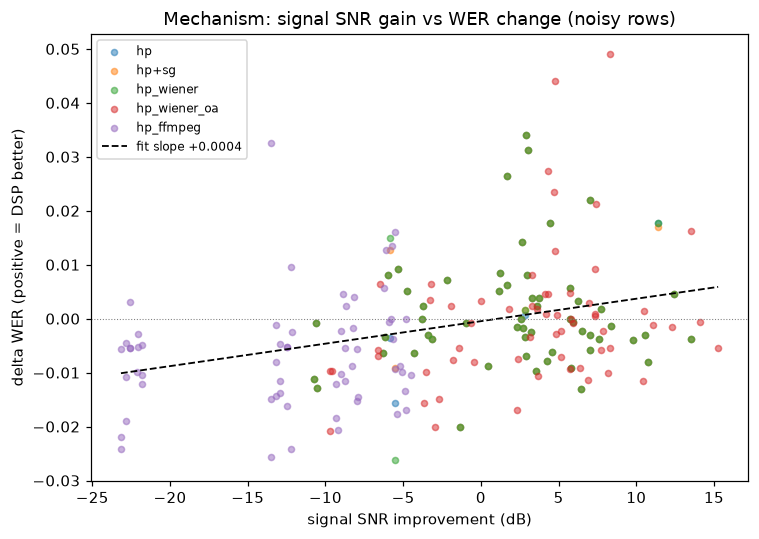

In [162]:
# H. spearman correlation: signal SNR improvement vs delta WER
noisy_h = d[d["noise_type"].astype(str) != "none"].copy()
base_snr = (df[df["condition"].astype(str) == "arm_a"][keys + ["signal_snr_improvement_db"]]
            .rename(columns={"signal_snr_improvement_db": "base_snr_gain"}))
noisy_h = noisy_h.merge(base_snr, on=keys, how="left", validate="many_to_one")
noisy_h["incr_snr_gain"] = noisy_h["signal_snr_improvement_db"] - noisy_h["base_snr_gain"]

def corr_report(xcol, label):
    rho, p = stats.spearmanr(noisy_h[xcol], noisy_h["delta_wer"], nan_policy="omit")
    print(f"{label}: rho={rho:.4f}, p={p:.4g}, n={int(noisy_h[xcol].notna().sum())}")
    for c in dsp_conds:
        sub = noisy_h[noisy_h["condition"].astype(str) == c]
        r, pp = stats.spearmanr(sub[xcol], sub["delta_wer"], nan_policy="omit")
        print(f"  {c}: rho={r:.4f}, p={pp:.4g}, n={int(sub[xcol].notna().sum())}")

corr_report("signal_snr_improvement_db", "raw DSP-reported SNR gain")
corr_report("incr_snr_gain", "baseline-adjusted incremental gain")

fig, ax = plt.subplots(figsize=(7, 5))
for i, c in enumerate(dsp_conds):
    sub = noisy_h[noisy_h["condition"].astype(str) == c]
    ax.scatter(sub["signal_snr_improvement_db"], sub["delta_wer"], s=16,
               color=plt.cm.tab10(i), label=c, alpha=0.5)
x = noisy_h["signal_snr_improvement_db"].to_numpy(float)
y = noisy_h["delta_wer"].to_numpy(float)
mask = np.isfinite(x) & np.isfinite(y)
if mask.sum() >= 2:
    m, b = np.polyfit(x[mask], y[mask], 1)
    xs = np.linspace(np.nanmin(x), np.nanmax(x), 100)
    ax.plot(xs, m * xs + b, color="black", linestyle="--", linewidth=1.2, label=f"fit slope {m:+.4f}")
ax.axhline(0, color="grey", linestyle=":", linewidth=0.7)
ax.set_xlabel("signal SNR improvement (dB)")
ax.set_ylabel("delta WER (positive = DSP better)")
ax.set_title("Mechanism: signal SNR gain vs WER change (noisy rows)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Reading it: a positive association supports “cleaner signal → better transcription”; a null or reversed association means the ASR is already robust or the SNR metric does not capture what matters.

## I. Summary table

One consolidated table, saved to `results_summary.csv`.

In [163]:
# I. consolidated summary
final_rows = []
for c in dsp_conds:
    x = d.loc[d["condition"] == c, "delta_wer"].to_numpy(float)
    sd = x.std(ddof=1)
    mean, lo, hi = cluster_ci(d[d["condition"] == c])
    w_p = safe_wilcoxon_p(x) if False else None
    # reuse safe function
    def _wp(a):
        a = np.asarray(a, float)
        if len(a) == 0: return np.nan
        if np.all(a == 0): return 1.0
        try: return float(stats.wilcoxon(a, zero_method="wilcox").pvalue)
        except ValueError: return np.nan
    w_p = _wp(x)
    w_p_holm = float(holm([w_p])[0]) if np.isfinite(w_p) else np.nan
    t_p = stats.ttest_1samp(x, 0.0).pvalue
    tost = tost_p(x, 0.005)
    wins = int((x > 0).sum()); losses = int((x < 0).sum()); ties = int((x == 0).sum())
    # mean extra RTF (DSP - baseline)
    rtf_base = df[df["condition"].astype(str) == "arm_a"][keys + ["rtf"]].rename(columns={"rtf": "rtf_base"})
    dd = df[df["condition"].astype(str) == c].merge(rtf_base, on=keys, how="left", validate="many_to_one")
    mean_drtf = float((dd["rtf"] - dd["rtf_base"]).mean())
    final_rows.append({"condition": c, "mean_delta_wer": mean, "sd_delta_wer": sd,
                       "ci_lo": lo, "ci_hi": hi, "ci_excludes_zero": bool((lo > 0) or (hi < 0)),
                       "wilcoxon_p": w_p, "wilcoxon_p_holm": w_p_holm,
                       "cohens_dz": (mean / sd if sd > 0 else np.nan),
                       "tost_p_margin_0.005": tost,
                       "wins": wins, "losses": losses, "ties": ties,
                       "mean_delta_rtf_extra": mean_drtf})

final_tbl = pd.DataFrame(final_rows).round(4)
final_tbl.to_csv("results_summary.csv", index=False)
final_tbl


,condition,mean_delta_wer,sd_delta_wer,ci_lo,ci_hi,ci_excludes_zero,wilcoxon_p,wilcoxon_p_holm,cohens_dz,tost_p_margin_0.005,wins,losses,ties,mean_delta_rtf_extra
0,hp,0.0010,0.0104,-0.0016,0.0043,False,0.9441,0.9441,0.0944,0.0014,26,36,3,0.0144
1,hp+sg,0.0013,0.0104,-0.0015,0.0053,False,0.8089,0.8089,0.1287,0.0030,27,35,3,0.0144
2,hp_wiener,0.0011,0.0109,-0.0015,0.0047,False,0.8361,0.8361,0.1024,0.0028,27,35,3,0.0150
3,hp_wiener_oa,0.0001,0.0126,-0.0030,0.0041,False,0.2626,0.2626,0.0063,0.0012,28,36,1,0.0136
4,hp_ffmpeg,-0.0066,0.0105,-0.0073,-0.0057,True,0.0000,0.0000,-0.6311,0.8922,11,52,2,0.0108


## Overall analysis and takeaways

**Q1 (does DSP improve transcription?):** Reported in `q1` and the summary table (`results_summary.csv`). For conditions with a cluster CI including 0 and a passing TOST, state there is **no detectable or practically meaningful effect**; only `hp_ffmpeg` shows a CI excluding 0 (clearly worse than baseline).

**Q2 (which is most / least impactful?):** Reported in `q2`/`rank_with_ci` and the best/worst counts. Treat the ranking as justified only if the Friedman test is significant; otherwise the apparent best/worst may be noise.

**Q3 (where/mechanism/cost):** The SNR plot shows effects are near zero for most conditions, with worse performance at high SNR and for `hp_ffmpeg`; the mixed model tests the condition × SNR interaction, and the Spearman/magnitude columns show whether signal-SNR gain predicts WER change. Use `mean_delta_rtf_extra` for the compute cost.

Each condition whose CI includes 0 AND whose TOST passes should be described as having **no detectable or practically meaningful effect** rather than as “no effect found.” n = 5 talks, 65 paired rows per condition.